# **TP4 : Architecture Transformer**

**Objectif du TP :** comprendre comment on est passé des réseaux récurrents (RNN, LSTM) aux Transformers (GPT, BERT). Pour chaque architecture, je regarde son principe, je l'implémente avec PyTorch, puis j'observe ses limites, qui expliquent pourquoi l'architecture suivante est apparue.

| Partie | Architecture | Données |
|--------|--------------|---------|
| 1 | RNN | Sinusoïde |
| 2 | LSTM | Sinusoïde |
| 3 | Transformer (encodeur) | Sinusoïde |
| 4 | GPT-2 (préentraîné) | Texte en anglais |
| 5 | BERT (préentraîné) | Texte en français |
| Exercice 1 | Transformer pour prédire une consommation électrique | Dataset UCI |
| Exercice 2 | Mini-GPT (génération de texte) | `corpus.txt` |
| Exercice 3 | Mini-BERT (mots masqués) | Petit corpus de phrases |

Les parties 1, 2 et 3 utilisent **exactement la même tâche** (prédire la valeur suivante d'une sinusoïde à partir des 10 précédentes). Les différences de résultat viennent donc uniquement de l'architecture.

## **Partie 1 : RNN**

Un **RNN** (réseau de neurones récurrent) lit une séquence **dans l'ordre** et garde une mémoire, l'**état caché** $h_t$, qu'il met à jour à chaque instant :

$$h_t = \tanh(W_{ih}x_t + W_{hh}h_{t-1} + b)$$

Les **mêmes poids** sont réutilisés à chaque instant : il y a une seule couche utilisée plusieurs fois dans le temps, pas plusieurs couches différentes.

### Étape 1 : préparer les données

> **Où en est-on ?** Partie 1 (RNN), étape 1 sur 4.
>
> **Objectif de la cellule :** créer une sinusoïde de 200 points, puis la découper par **fenêtre glissante** : 10 valeurs en entrée, la 11ᵉ comme cible. On obtient 190 exemples de forme `(190, 10, 1)`, car un RNN attend `(séquences, longueur, variables)`.
>
> Le découpage est **chronologique** : 150 exemples pour l'entraînement, 40 pour le test. On teste ainsi le modèle sur un « futur » qu'il n'a jamais vu.

In [1]:
import torch
import torch.nn as nn
torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10
# Chaque entrée contient 10 valeurs.
# La cible est la valeur immédiatement suivante.
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
# Un RNN attend : (nombre de séquences, longueur, nombre de variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : début pour apprendre, fin pour tester.
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

**Objectif de la cellule :** tracer la série pour vérifier qu'on obtient bien une sinusoïde avant de modéliser.

Text(0, 0.5, 'y')

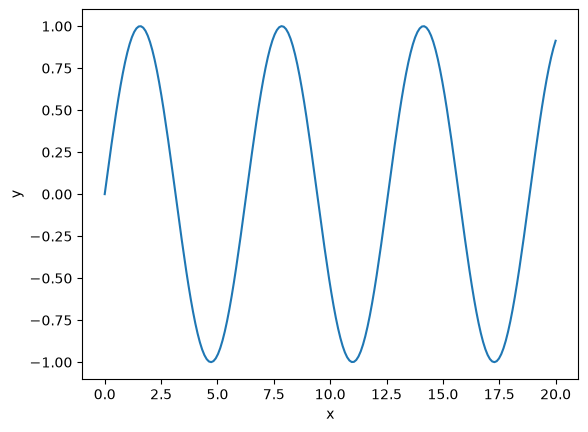

In [2]:
import matplotlib.pyplot as plt
plt.plot(periode, serie)
plt.xlabel("x")
plt.ylabel("y")

### Étape 2 : définir le modèle

**Objectif de la cellule :** construire le réseau, la fonction de perte et l'optimiseur.

- `nn.RNN(input_size=1, hidden_size=16)` : lit la séquence valeur par valeur, avec une mémoire de 16 nombres.
- `nn.Linear(16, 1)` : transforme le **dernier** état caché en une prédiction.
- `MSELoss` : c'est un problème de **régression**, on mesure l'écart entre la valeur prédite et la valeur réelle.
- `Adam(lr=0.01)` : met à jour les poids.

Dimensions : `(B, 10, 1)` → RNN → `(B, 10, 16)` → dernier état → `(B, 16)` → Linear → `(B, 1)`.

In [3]:
# --------------------------------------------------
# 2. Définir le modèle
# --------------------------------------------------

class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,     # Une valeur à chaque instant
            hidden_size=16,   # Une mémoire composée de 16 nombres
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Si aucun état initial n'est fourni, PyTorch utilise des zéros.
        etats, _ = self.rnn(x)

        # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Transformer la mémoire finale en une valeur prédite.
        return self.sortie(dernier_etat)


modele = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

### Étape 3 : entraîner puis tester

**Objectif de la cellule :** pendant 300 époques, prédire, mesurer l'erreur, calculer les gradients (`backward`) et corriger les poids (`step`). Ensuite, évaluer sur les 40 exemples de test pour vérifier que le modèle **généralise**.

**Résultat :** l'erreur d'entraînement diminue de ≈ 1,3·10⁻³ (époque 50) à ≈ 2,5·10⁻⁵ (époque 300). L'erreur de test est d'environ **2,8·10⁻⁵**. La première prédiction (-0,3601) est très proche de la vraie valeur (-0,3639).

In [4]:
# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()  # Effacer les anciens gradients
    perte.backward()       # Calculer les nouveaux gradients
    optimiseur.step()      # Mettre à jour les paramètres

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001277


Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223


Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049


Epoch 300 | Erreur : 0.000025

Erreur de test : 0.000028
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


**Objectif de la cellule :** vérifier la forme des prédictions : `(40, 1)`, une valeur par exemple de test.

In [5]:
predictions.shape

torch.Size([40, 1])

### Étape 4 : visualiser les prédictions

**Objectif de la cellule :** superposer la courbe réelle (bleu) et la courbe prédite (rouge). Quand elles sont presque confondues, le modèle a bien appris la forme de la sinusoïde.

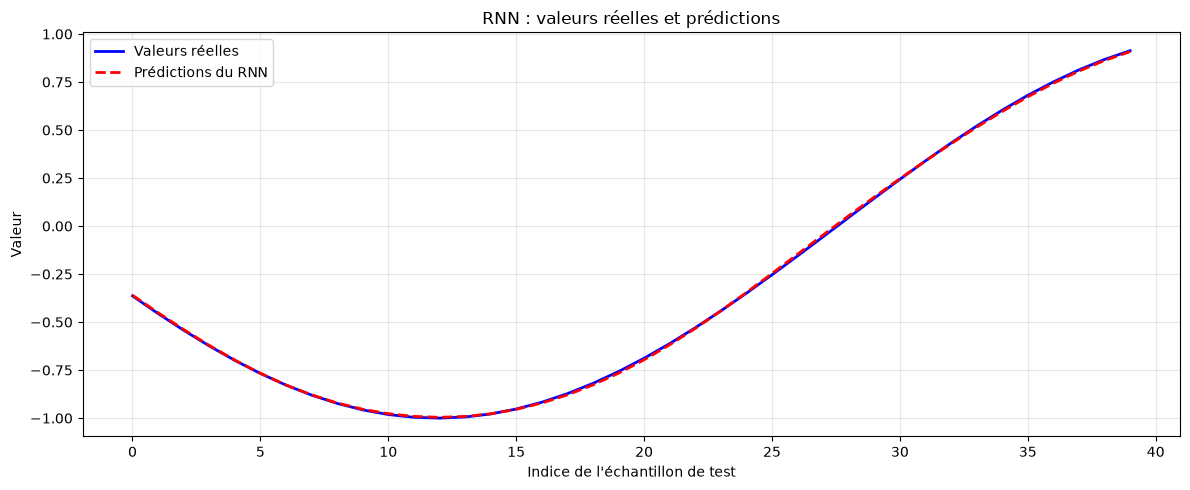

In [6]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du RNN",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Limites du RNN

Le RNN marche bien ici, mais la tâche est facile (10 pas, aucun bruit). Sur des séquences plus longues, il montre ses limites :

- **Gradients qui disparaissent ou explosent** : la rétropropagation à travers le temps multiplie le gradient à chaque pas. Il devient quasi nul (ou énorme), donc le réseau n'apprend plus l'effet des entrées lointaines.
- **Mémoire courte** : `h_t` est entièrement réécrit à chaque pas, donc les informations anciennes s'écrasent.
- **Calcul séquentiel** : `h_t` dépend de `h_{t-1}`, donc on ne peut pas paralléliser.

→ Le **LSTM** a été créé pour mieux gérer la mémoire.

---

## **Partie 2 : LSTM**

Un **LSTM** transmet **deux** états : l'état caché $h_t$ et l'**état de cellule** $c_t$ (la mémoire interne). Trois **portes** (valeurs entre 0 et 1) contrôlent l'information :

| Porte | Rôle |
|-------|------|
| Oubli $f_t$ | Quoi garder de l'ancienne mémoire |
| Entrée $i_t$ | Quoi ajouter à la mémoire |
| Sortie $o_t$ | Quoi exposer dans $h_t$ |

> **Où en est-on ?** Partie 2 (LSTM), même tâche que le RNN pour comparer équitablement.
>
> **Objectif de la cellule :** refaire les 4 étapes (données, modèle, entraînement, test) en remplaçant seulement `nn.RNN` par `nn.LSTM`.

| | RNN | LSTM |
|---|-----|------|
| États | `h` | `h` et `c` |
| Mécanisme | `tanh` direct | 3 portes + contenu candidat |
| Paramètres de la couche (ici) | 304 | 1 216 (4 fois plus) |

**Résultat :** erreur de test ≈ **3·10⁻⁶**, soit environ 10 fois moins que le RNN.

In [7]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme attendue : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle LSTM
# --------------------------------------------------

class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,     # Une variable à chaque instant
            hidden_size=16,   # 16 unités cachées
            num_layers=1,     # Une seule couche LSTM
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Sans états initiaux fournis, h₀ et c₀ sont mis à zéro.
        etats, (h_final, c_final) = self.lstm(x)

        # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Une prédiction par séquence
        return self.sortie(dernier_etat)


modele = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248


Epoch 150 | Erreur : 0.000043
Epoch 200 | Erreur : 0.000006


Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003

Erreur de test : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


**Objectif de la cellule :** même graphique que pour le RNN, pour comparer visuellement.

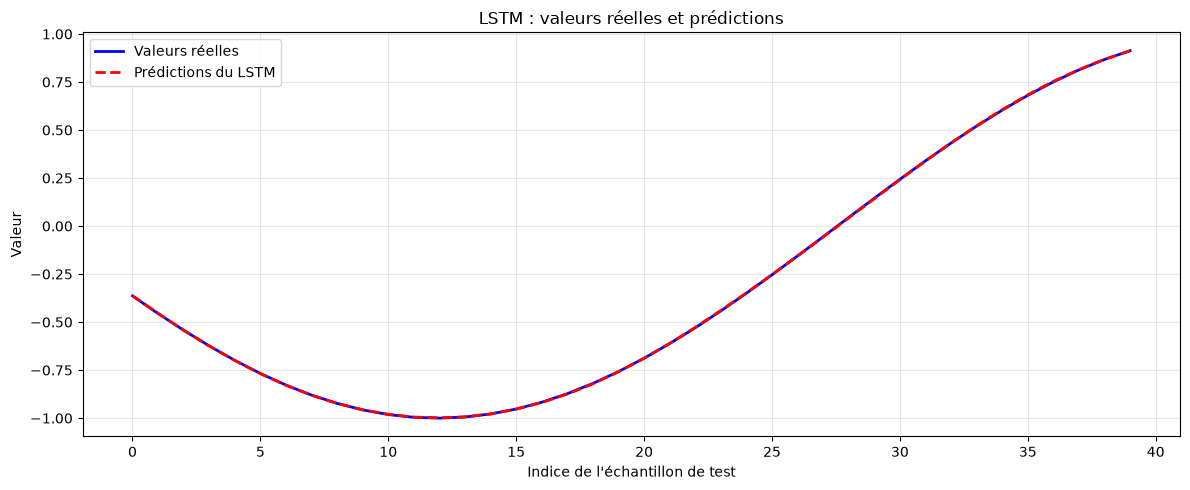

In [8]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du LSTM",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Bilan RNN / LSTM

| Modèle | Erreur de test | 1ʳᵉ prédiction (réel = -0,3639) |
|--------|----------------|---------------------------------|
| RNN | ≈ 2,8·10⁻⁵ | -0,3601 |
| LSTM | ≈ 3·10⁻⁶ | -0,3622 |

Le LSTM est meilleur ici, mais c'est une seule exécution sur un problème facile : son vrai avantage se voit sur des séquences **longues**.

**Limites qui restent :** calcul toujours séquentiel, toute l'information passée doit tenir dans un vecteur de taille fixe, et modèle plus lourd.

→ Le **Transformer** supprime la récurrence : l'**attention** relie directement toutes les positions.

---

## **Partie 3 : Transformer**

Un **Transformer** n'a pas de mémoire récurrente : chaque position regarde directement les autres grâce à l'**attention**. À partir des entrées, on calcule trois ensembles de vecteurs : **Q** (ce que chaque position cherche), **K** (ce qu'elle propose) et **V** (l'information à combiner).

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

L'attention **multi-têtes** fait plusieurs de ces calculs en parallèle. Comme l'attention ne connaît pas l'ordre, on **ajoute l'information de position**.

> **Où en est-on ?** Partie 3 (Transformer, encodeur seul), même tâche.
>
> **Objectif de la cellule :** construire un mini-Transformer, l'entraîner et le tester.

| Étape de `forward` | Dimensions |
|--------------------|------------|
| Projection `Linear(1, 16)` | `(B, 10, 1)` → `(B, 10, 16)` |
| + position `Embedding(10, 16)` | `(B, 10, 16)` |
| Encodeur (auto-attention 2 têtes + feed-forward) | `(B, 10, 16)` |
| Dernière position | `(B, 16)` |
| `Linear(16, 1)` | `(B, 1)` |

**Résultat :** erreur de test ≈ **6·10⁻⁶**.

In [9]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle Transformer
# --------------------------------------------------

class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()

        dimension = 16

        # Transformer chaque valeur en un vecteur de 16 nombres.
        self.projection = nn.Linear(1, dimension)

        # Un vecteur appris pour chacune des 10 positions.
        self.positions = nn.Embedding(longueur_max, dimension)

        # Un bloc d'encodeur Transformer.
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,       # Taille des représentations : 16
            nhead=2,                 # Deux têtes d'attention
            dim_feedforward=32,      # Taille interne du réseau feed-forward
            dropout=0.0,             # Désactivé pour simplifier l'exemple
            batch_first=True
        )

        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=1
        )

        # Transformer la représentation finale en une prédiction.
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        # x : (B, 10, 1)
        longueur = x.size(1)

        # 1. Projection des valeurs
        x = self.projection(x)  # (B, 10, 16)

        # 2. Ajout de l'information de position
        indices = torch.arange(longueur, device=x.device)
        positions = self.positions(indices)  # (10, 16)

        x = x + positions.unsqueeze(0)  # (B, 10, 16)

        # 3. Mise en relation des valeurs par auto-attention
        representations = self.encodeur(x)  # (B, 10, 16)

        # 4. Récupérer la représentation de la dernière position
        derniere_position = representations[:, -1, :]  # (B, 16)

        # 5. Prédire la valeur suivante
        return self.sortie(derniere_position)  # (B, 1)


modele = MiniTransformer(longueur_max=longueur_sequence)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001504


Epoch 100 | Erreur : 0.000110


Epoch 150 | Erreur : 0.000026


Epoch 200 | Erreur : 0.000012


Epoch 250 | Erreur : 0.000007


Epoch 300 | Erreur : 0.000004

Erreur de test : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


**Objectif de la cellule :** même graphique (réel et prédit) pour le Transformer.

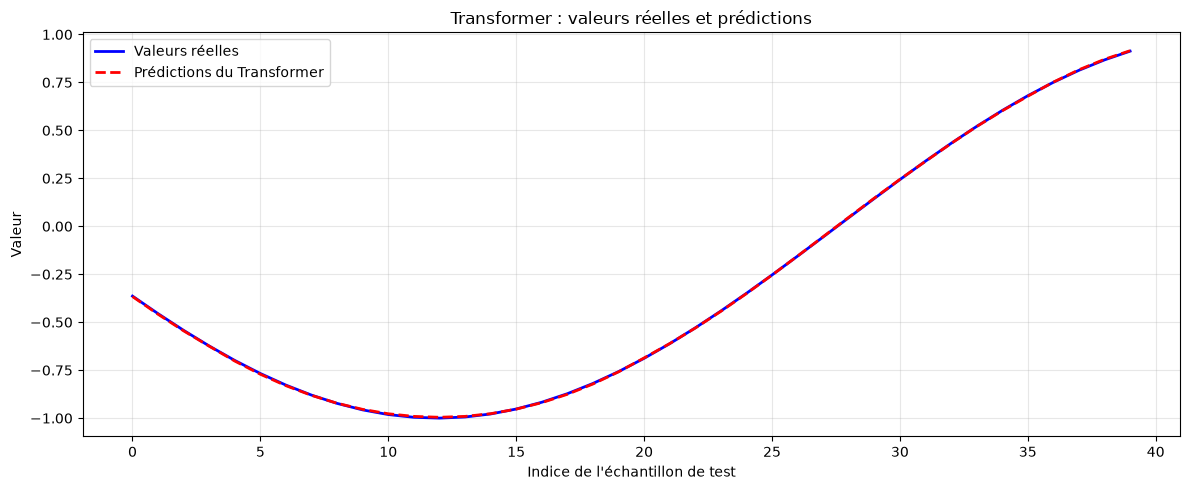

In [10]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du Transformer",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Comparaison RNN / LSTM / Transformer

| Modèle | Erreur de test |
|--------|----------------|
| RNN | ≈ 2,8·10⁻⁵ |
| LSTM | ≈ 3·10⁻⁶ |
| Transformer | ≈ 6·10⁻⁶ |

Les trois réussissent. Le Transformer n'est pas avantagé ici : la tâche est minuscule. Il brille sur de longues séquences et de gros volumes de données.

| Critère | RNN | LSTM | Transformer |
|---------|-----|------|-------------|
| Traitement | Pas à pas | Pas à pas | **En parallèle** |
| Mémoire | `h_t` | `h_t` + `c_t` (portes) | Attention sur toute la séquence |
| Dépendances lointaines | Difficile | Meilleur | **Accès direct** |
| Position | Implicite | Implicite | **À ajouter** |
| Coût | Linéaire | Linéaire | **Quadratique** |

**Limites du Transformer :** coût quadratique avec la longueur, besoin de beaucoup de données, dépendance à l'encodage de position.

---

## **Partie 4 : GPT**

On passe au langage avec un modèle **déjà entraîné** (GPT-2) : on ne l'entraîne pas, on l'utilise.

> **Objectif de la cellule :** charger le tokenizer (texte → identifiants) et GPT-2, encoder la phrase `"Artificial intelligence can help people"`, puis **générer la suite** token par token.

**Principe :** GPT est un **décodeur** avec une **attention causale** : chaque position ne voit que les précédentes. Il prédit le token suivant, l'ajoute au texte, puis recommence. C'est la **génération autorégressive**.

Le premier lancement télécharge le modèle, ce qui explique le temps d'attente et les avertissements Hugging Face (token, symlinks) : ils ne bloquent rien. Avec `do_sample=True`, le texte change d'une exécution à l'autre, et il est fluide mais pas forcément exact : le modèle choisit des mots probables, il ne vérifie pas les faits.

In [11]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForCausalLM.from_pretrained(nom_modele)

# GPT-2 ne possède pas de token de padding dédié.
tokenizer.pad_token = tokenizer.eos_token
modele.config.pad_token_id = tokenizer.pad_token_id

modele.eval()

# --------------------------------------------------
# 2. Transformer le texte en tokens
# --------------------------------------------------

# GPT-2 est principalement entraîné sur de l'anglais.
texte = "Artificial intelligence can help people"

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# --------------------------------------------------
# 3. Générer la suite, un token après l'autre
# --------------------------------------------------

with torch.no_grad():
    sortie = modele.generate(
        **entrees,
        max_new_tokens=50,       # Générer au maximum 50 tokens
        do_sample=True,          # Tirage aléatoire des tokens
        temperature=0.8,         # Contrôler la diversité
        top_p=0.9,               # Limiter les candidats probables
        pad_token_id=tokenizer.pad_token_id
    )

# --------------------------------------------------
# 4. Reconvertir les tokens en texte
# --------------------------------------------------

texte_genere = tokenizer.decode(
    sortie[0],
    skip_special_tokens=True
)

print("\nTexte généré :")
print(texte_genere)

C:\Users\DELL\Documents\IA\tp4_Architecture_Transformer\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   5%|▍         | 7/148 [00:00<00:02, 61.31it/s]

Loading weights:   9%|▉         | 14/148 [00:00<00:03, 37.47it/s]

Loading weights:  13%|█▎        | 19/148 [00:00<00:05, 22.65it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 197.69it/s]

Dimensions de l'entrée : torch.Size([1, 6])



Texte généré :
Artificial intelligence can help people and organizations create jobs and build organizations, which in turn will spur growth and prosperity.

However, when a company becomes more complex, it's likely that its users will be less interested in technology. The companies that make the software that makes things


## **Partie 5 : BERT**

> **Objectif de la cellule :** utiliser BERT multilingue pour retrouver le mot masqué dans `Rabat est la [MASK] Maroc.`

**Résultat :** « capitale » arrive en tête (≈ **43 %**), loin devant « du » (≈ 21 %). BERT a utilisé le contexte **des deux côtés** du masque : « Rabat » à gauche, « Maroc » à droite. L'avertissement « UNEXPECTED » au chargement est normal : on ne charge que la partie utile à cette tâche.

**Comparaison GPT / BERT :**

| Critère | GPT | BERT |
|---------|-----|------|
| Bloc | Décodeur | Encodeur |
| Attention | Causale (regarde le passé) | Bidirectionnelle (gauche et droite) |
| Entraînement | Prédire le token suivant | Retrouver des tokens masqués |
| Point fort | **Générer** du texte | **Comprendre** le texte |

In [12]:
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForMaskedLM.from_pretrained(nom_modele)

modele.eval()

# --------------------------------------------------
# 2. Préparer un texte avec un token masqué
# --------------------------------------------------

texte = f"Rabat est la {tokenizer.mask_token} Maroc."

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Texte :", texte)
print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# Repérer la position du masque dans la séquence
position_masque = (
    entrees["input_ids"][0] == tokenizer.mask_token_id
).nonzero(as_tuple=True)[0].item()

# --------------------------------------------------
# 3. Prédire le token masqué
# --------------------------------------------------

with torch.no_grad():
    sortie = modele(**entrees)

# sortie.logits : (1, nombre de tokens, taille du vocabulaire)
scores = sortie.logits[0, position_masque, :]

# Transformer les scores en probabilités
probabilites = torch.softmax(scores, dim=-1)

# Sélectionner les 5 tokens les plus probables
top_probabilites, top_indices = torch.topk(probabilites, k=5)

# --------------------------------------------------
# 4. Afficher les propositions
# --------------------------------------------------

print("\nPropositions de BERT :")

for probabilite, indice in zip(top_probabilites, top_indices):
    token = tokenizer.decode([indice.item()]).strip()

    phrase = texte.replace(tokenizer.mask_token, token)

    print(f"{probabilite.item():.2%} | {phrase}")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   9%|▉         | 18/202 [00:00<00:01, 174.26it/s]

Loading weights:  18%|█▊        | 36/202 [00:00<00:01, 113.97it/s]

Loading weights:  24%|██▍       | 49/202 [00:00<00:01, 116.08it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 470.15it/s]


[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Texte : Rabat est la [MASK] Maroc.
Dimensions de l'entrée : torch.Size([1, 8])

Propositions de BERT :
42.90% | Rabat est la capitale Maroc.
20.66% | Rabat est la du Maroc.
6.23% | Rabat est la de Maroc.
3.46% | Rabat est la ville Maroc.
1.67% | Rabat est la Rabat Maroc.


---
# **Exercices**

## **Exercice 1 : prédire la consommation électrique avec un Transformer**

**Objectif :** utiliser les **24 dernières heures** de consommation pour prédire celle de l'heure suivante.

**Données :** *Individual Household Electric Power Consumption* (UCI), variable `Global_active_power`, agrégée par heure pour obtenir une puissance moyenne en kW.

### 1. Préparation des données

> **Objectif de la cellule (fournie) :**
> - lire `household_power_consumption.txt` (≈ 2 millions de mesures à la minute, `?` = valeur manquante) ;
> - calculer la **puissance moyenne par heure**, en gardant seulement les heures avec au moins 45 mesures sur 60 ;
> - découper **chronologiquement** : 70 % entraînement, 15 % validation, 15 % test ;
> - **normaliser** avec la moyenne et l'écart-type de l'entraînement uniquement ;
> - créer des fenêtres de 24 heures et les mettre dans des `DataLoader` (batch de 64).

In [13]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False,
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
)

puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

# Puissance moyenne horaire : conserver les heures suffisamment renseignées.
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

# Découpage chronologique : 70 % entraînement, 15 % validation, 15 % test.
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

# Normalisation calculée uniquement sur l'entraînement.
moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

# Une entrée contient 24 heures consécutives.
# Écarter les fenêtres comportant des valeurs manquantes.
fenetre = 24
X, y, dates_cibles = [], [], []

for i in range(fenetre, n):
    sequence = valeurs[i - fenetre:i]
    cible = valeurs[i]

    if np.isfinite(sequence).all() and np.isfinite(cible):
        X.append(sequence)
        y.append(cible)
        dates_cibles.append(i)

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
dates_cibles = np.array(dates_cibles)

train_mask = dates_cibles < fin_train
val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
test_mask = dates_cibles >= fin_val

train_loader = DataLoader(
    TensorDataset(X[train_mask], y[train_mask]),
    batch_size=64,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(X[val_mask], y[val_mask]),
    batch_size=64,
)
test_loader = DataLoader(
    TensorDataset(X[test_mask], y[test_mask]),
    batch_size=64,
)

**Objectif de la cellule (ajoutée) :** afficher les variables créées pour vérifier la préparation : 34 589 heures, 33 791 exemples de forme `(24, 1)`, répartis en 23 805 pour l'entraînement, 5 054 pour la validation et 4 932 pour le test. Il y a moins d'exemples que d'heures parce que les fenêtres contenant une valeur manquante ont été écartées.

In [14]:
# Vérification des variables créées dans la cellule précédente

print("=== Série horaire ===")
print("Nombre d'heures (n)        :", n)
print("Période                    :", serie.index.min(), "->", serie.index.max())
print("Heures manquantes (NaN)    :", int(serie.isna().sum()))
print("Moyenne (train)            : %.4f kW" % moyenne)
print("Écart-type (train)         : %.4f kW" % ecart_type)

print("\n=== Découpage chronologique ===")
print("fin_train, fin_val         :", fin_train, fin_val)
print("Fenêtre                    :", fenetre, "heures")

print("\n=== Tenseurs ===")
print("X (entrées)                :", tuple(X.shape), "-> (exemples, 24 heures, 1 variable)")
print("y (cibles)                 :", tuple(y.shape), "-> (exemples, 1)")

print("\n=== Nombre d'exemples par jeu ===")
print("Train                      :", int(train_mask.sum()))
print("Validation                 :", int(val_mask.sum()))
print("Test                       :", int(test_mask.sum()))

print("\n=== DataLoaders ===")
print("Batches train / val / test :", len(train_loader), "/", len(val_loader), "/", len(test_loader))
X_batch, y_batch = next(iter(train_loader))
print("Un batch                   : X", tuple(X_batch.shape), "| y", tuple(y_batch.shape))

print("\n=== Exemple (valeurs normalisées) ===")
print("Premier X[0] (24 valeurs)  :", X[0].squeeze().numpy().round(2))
print("Sa cible y[0]              :", round(y[0].item(), 2))
print("Même valeur en kW          : %.3f" % (y[0].item() * ecart_type + moyenne))

=== Série horaire ===
Nombre d'heures (n)        : 34589
Période                    : 2006-12-16 17:00:00 -> 2010-11-26 21:00:00
Heures manquantes (NaN)    : 438
Moyenne (train)            : 1.0865 kW
Écart-type (train)         : 0.9287 kW

=== Découpage chronologique ===
fin_train, fin_val         : 24212 29400
Fenêtre                    : 24 heures

=== Tenseurs ===
X (entrées)                : (33791, 24, 1) -> (exemples, 24 heures, 1 variable)
y (cibles)                 : (33791, 1) -> (exemples, 1)

=== Nombre d'exemples par jeu ===
Train                      : 23805
Validation                 : 5054
Test                       : 4932

=== DataLoaders ===
Batches train / val / test : 372 / 79 / 78
Un batch                   : X (64, 24, 1) | y (64, 1)

=== Exemple (valeurs normalisées) ===
Premier X[0] (24 valeurs)  : [2.74 2.49 2.35 2.12 1.2  1.05 0.86 2.44 0.54 0.62 1.22 0.98 0.23 0.57
 0.87 1.57 2.74 1.49 0.89 0.62 1.08 2.04 2.41 2.5 ]
Sa cible y[0]              : 2.81
Même vale

### 2. Implémentation : `EnergyTransformer`

> **Objectif de la cellule :** construire le modèle demandé :
> - projection `Linear(1, 32)` : chaque heure devient un vecteur de 32 nombres ;
> - **encodage positionnel appris** pour les 24 positions (`nn.Embedding(24, 32)`) ;
> - 2 couches `TransformerEncoderLayer` (`d_model=32`, `nhead=4`, `dim_feedforward=128`, `dropout=0.1`) ;
> - `Linear(32, 1)` appliquée à la **dernière heure** (celle qui a vu les 23 autres grâce à l'attention).
>
> Je vérifie ensuite les dimensions : `(batch, 24, 1)` → `(batch, 24, 32)` → `(batch, 24, 32)` → `(batch, 1)`, comme dans l'énoncé.

In [15]:
import torch.nn as nn

class EnergyTransformer(nn.Module):
    def __init__(self, fenetre=24, dimension=32):
        super().__init__()

        # Chaque heure (1 valeur) devient un vecteur de 32 nombres.
        self.projection = nn.Linear(1, dimension)

        # Un vecteur appris pour chacune des 24 positions (heures).
        self.positions = nn.Embedding(fenetre, dimension)

        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(
            couche, num_layers=2, enable_nested_tensor=False
        )

        # La prédiction utilise la représentation de la dernière heure.
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        # x : (batch, 24, 1)
        x = self.projection(x)                                    # (batch, 24, 32)
        indices = torch.arange(x.size(1), device=x.device)
        x = x + self.positions(indices).unsqueeze(0)              # (batch, 24, 32)
        x = self.encodeur(x)                                      # (batch, 24, 32)
        return self.sortie(x[:, -1, :])                           # (batch, 1)

# Vérification des dimensions sur un batch
energie = EnergyTransformer()
xb, yb = next(iter(train_loader))
print("Entrée                    :", tuple(xb.shape))
print("Après projection          :", tuple(energie.projection(xb).shape))
print("Après Transformer Encoder :", tuple(energie.encodeur(energie.projection(xb) + energie.positions(torch.arange(24)).unsqueeze(0)).shape))
print("Prédiction                :", tuple(energie(xb).shape))
print("Paramètres                :", sum(p.numel() for p in energie.parameters()))

Entrée                    : (64, 24, 1)
Après projection          : (64, 24, 32)
Après Transformer Encoder : (64, 24, 32)
Prédiction                : (64, 1)
Paramètres                : 26273


### 3. Entraînement

> **Objectif de la cellule :** entraîner avec Adam (`lr=0.001`) et une perte MSE pendant 20 époques, et **garder le modèle qui a la meilleure perte de validation** (copie de ses poids à chaque amélioration).
>
> **Ce que j'observe :** la perte d'entraînement baisse régulièrement (0,47 → 0,39), la perte de validation se stabilise vers 0,38. La meilleure validation est à l'époque 18, donc pas de surapprentissage marqué. Les deux courbes restent proches.

In [16]:
import copy

torch.manual_seed(42)
energie = EnergyTransformer()
critere_energie = nn.MSELoss()
optimiseur_energie = torch.optim.Adam(energie.parameters(), lr=0.001)

def perte_moyenne(modele, loader):
    # Perte MSE moyenne sur tout un jeu de données (sans mise à jour des poids).
    modele.eval()
    somme, total = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            somme += critere_energie(modele(xb), yb).item() * len(xb)
            total += len(xb)
    return somme / total

meilleure_val = float("inf")
meilleur_etat = None
meilleure_epoque = 0
hist_train, hist_val = [], []

for epoch in range(1, 21):
    energie.train()
    somme, total = 0.0, 0
    for xb, yb in train_loader:
        perte = critere_energie(energie(xb), yb)
        optimiseur_energie.zero_grad()
        perte.backward()
        optimiseur_energie.step()
        somme += perte.item() * len(xb)
        total += len(xb)

    perte_train = somme / total
    perte_val = perte_moyenne(energie, val_loader)
    hist_train.append(perte_train)
    hist_val.append(perte_val)

    # Conserver le modèle ayant la meilleure perte de validation.
    if perte_val < meilleure_val:
        meilleure_val = perte_val
        meilleur_etat = copy.deepcopy(energie.state_dict())
        meilleure_epoque = epoch

    print(f"Epoch {epoch:2d} | train : {perte_train:.4f} | validation : {perte_val:.4f}")

energie.load_state_dict(meilleur_etat)
print(f"\nMeilleur modèle : époque {meilleure_epoque} (perte de validation {meilleure_val:.4f})")

Epoch  1 | train : 0.4698 | validation : 0.4081


Epoch  2 | train : 0.4324 | validation : 0.3935


Epoch  3 | train : 0.4256 | validation : 0.3968


Epoch  4 | train : 0.4182 | validation : 0.3862


Epoch  5 | train : 0.4152 | validation : 0.3819


Epoch  6 | train : 0.4123 | validation : 0.3908


... (10 outputs left out)

Epoch 17 | train : 0.3954 | validation : 0.3815


Epoch 18 | train : 0.3961 | validation : 0.3795


Epoch 19 | train : 0.3967 | validation : 0.3814


Epoch 20 | train : 0.3925 | validation : 0.3836

Meilleur modèle : époque 18 (perte de validation 0.3795)


### Évaluation sur le test

> **Objectif de la cellule :**
> 1. prédire sur le test et revenir en **kW** avec `valeur * ecart_type + moyenne` ;
> 2. calculer la **MAE** (erreur moyenne en valeur absolue) et la **RMSE** (qui pénalise plus les grosses erreurs) ;
> 3. comparer avec deux références simples :
>    - **persistance** : on prédit la dernière heure observée ;
>    - **référence journalière** : on prédit la valeur observée 24 heures plus tôt.
>
> L'évaluation est faite heure par heure : chaque prédiction utilise les 24 mesures réellement observées juste avant.

| Modèle | MAE (kW) | RMSE (kW) |
|--------|----------|-----------|
| **Transformer** | **0,342** | **0,491** |
| Persistance (h-1) | 0,389 | 0,588 |
| Référence journalière (h-24) | 0,513 | 0,764 |

In [17]:
X_test, y_test = X[test_mask], y[test_mask]

# Prédictions du Transformer sur le test (échelle normalisée)
energie.eval()
with torch.no_grad():
    pred_norm = torch.cat([energie(xb) for xb, _ in test_loader]).squeeze(1).numpy()

# Retour à l'échelle d'origine : valeur * ecart_type + moyenne
def en_kw(v):
    return v * ecart_type + moyenne

reel = en_kw(y_test.squeeze(1).numpy())
pred_transformer = en_kw(pred_norm)
pred_persistance = en_kw(X_test[:, -1, 0].numpy())   # dernière heure observée
pred_journaliere = en_kw(X_test[:, 0, 0].numpy())    # même heure, la veille (24 h avant)

def mae(a, b):
    return float(np.mean(np.abs(a - b)))

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

resultats = pd.DataFrame({
    "MAE (kW)": [mae(pred_transformer, reel), mae(pred_persistance, reel), mae(pred_journaliere, reel)],
    "RMSE (kW)": [rmse(pred_transformer, reel), rmse(pred_persistance, reel), rmse(pred_journaliere, reel)],
}, index=["Transformer", "Persistance (h-1)", "Référence journalière (h-24)"])

print("Nombre d'exemples de test :", len(reel))
print(resultats.round(4))

Nombre d'exemples de test : 4932
                              MAE (kW)  RMSE (kW)
Transformer                     0.3424     0.4913
Persistance (h-1)               0.3892     0.5884
Référence journalière (h-24)    0.5133     0.7639


### Visualisation

> **Objectif de la cellule :** tracer sur **7 jours consécutifs** du test (168 heures sans trou) les observations, les prédictions du Transformer et la persistance, puis les courbes d'apprentissage.
>
> **Ce que j'observe :** le Transformer suit le rythme quotidien (creux autour de 0,4 kW la nuit, pics dans la journée et la soirée). Il **lisse les pics très brusques** : il les prédit souvent plus bas que la réalité, parce qu'une consommation ponctuelle (un appareil qui s'allume) est difficile à deviner à partir de l'historique seul. La courbe grise de la persistance est simplement la courbe observée **décalée d'une heure** : elle arrive toujours en retard sur les montées et les descentes.

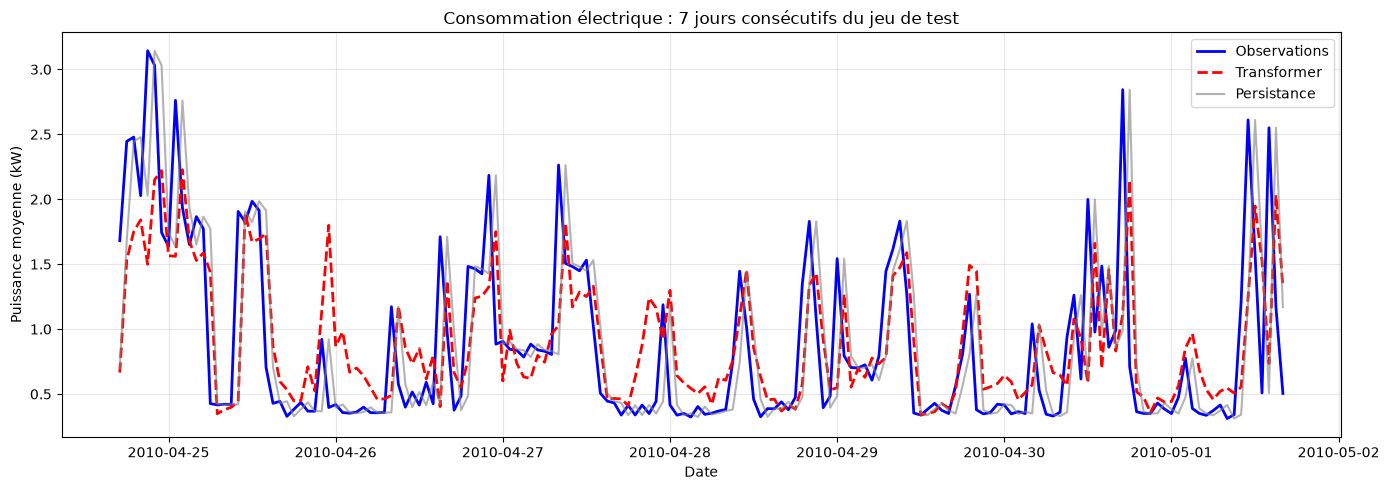

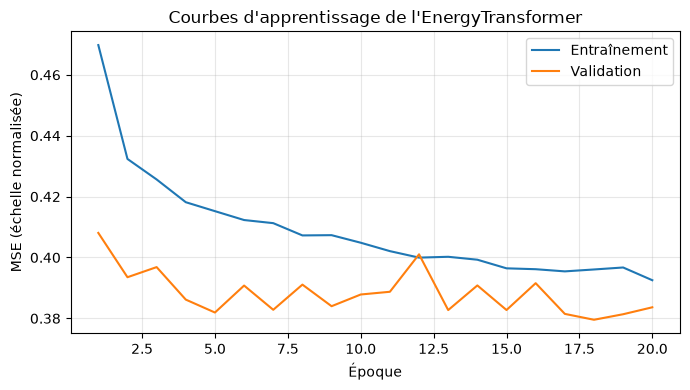

In [18]:
import matplotlib.pyplot as plt

# Chercher 7 jours consécutifs (168 heures) dans le test, sans heure manquante.
indices_test = dates_cibles[test_mask]
debut = None
for s in range(len(indices_test) - 168):
    if (np.diff(indices_test[s:s + 169]) == 1).all():
        debut = s
        break

fenetre_7j = slice(debut, debut + 168)
heures = serie.index[indices_test[fenetre_7j]]

plt.figure(figsize=(14, 5))
plt.plot(heures, reel[fenetre_7j], label="Observations", color="blue", linewidth=2)
plt.plot(heures, pred_transformer[fenetre_7j], label="Transformer", color="red", linestyle="--", linewidth=2)
plt.plot(heures, pred_persistance[fenetre_7j], label="Persistance", color="gray", alpha=0.6)
plt.title("Consommation électrique : 7 jours consécutifs du jeu de test")
plt.xlabel("Date")
plt.ylabel("Puissance moyenne (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Courbes d'apprentissage
plt.figure(figsize=(7, 4))
plt.plot(range(1, 21), hist_train, label="Entraînement")
plt.plot(range(1, 21), hist_val, label="Validation")
plt.xlabel("Époque")
plt.ylabel("MSE (échelle normalisée)")
plt.title("Courbes d'apprentissage de l'EnergyTransformer")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Questions de réflexion : exercice 1

**1. Le Transformer améliore-t-il les deux références ?**
Oui. Sa MAE (0,342 kW) est plus faible que celle de la persistance (0,389 kW, soit environ 12 % de mieux) et que celle de la référence journalière (0,513 kW). Sa RMSE (0,491 kW) est aussi meilleure (≈ 17 % de moins que la persistance). Le gain reste modeste : la consommation d'une heure ressemble déjà beaucoup à celle de l'heure précédente. C'est un seul entraînement sur un seul découpage, donc je ne généralise pas.

**2. Une fenêtre de 168 heures capture-t-elle mieux les habitudes hebdomadaires ?**
Je n'ai pas de mesure : un essai avec 168 heures a été trop long sur cette machine (plus d'une heure pour 10 époques), donc je réponds par le raisonnement. Avec 24 heures, le modèle ne voit jamais « la même heure la semaine dernière », il ne peut donc pas apprendre qu'un samedi diffère d'un mardi. Avec 168 heures, l'attention peut relier directement l'heure cible aux mêmes heures des jours précédents, ce qui devrait aider. Le prix est un calcul d'attention environ 49 fois plus coûteux (168² contre 24²) et davantage de paramètres de position à apprendre.

**3. Intérêt d'ajouter l'heure de la journée et le jour de la semaine ?**
L'encodage positionnel indique seulement la place dans la fenêtre (de 0 à 23), pas l'heure réelle ni le jour. Or la consommation dépend fortement de l'heure (pics du matin et du soir) et du jour (week-end). Ajouter ces informations, par exemple sous forme de sinus et cosinus pour que 23 h soit proche de 0 h, donnerait au modèle des repères calendaires. L'entrée passerait de `(batch, 24, 1)` à `(batch, 24, nombre_de_variables)`, avec `Linear(nombre_de_variables, 32)`.

**4. Pourquoi normaliser uniquement à partir de l'entraînement ?**
Parce que la validation et le test représentent des données **inconnues au moment de l'entraînement**. Calculer la moyenne et l'écart-type avec elles ferait fuiter de l'information du futur vers le modèle (*data leakage*) et rendrait l'évaluation trop optimiste. On calcule donc ces deux valeurs sur l'entraînement, puis on les applique telles quelles aux trois jeux.

**5. Prédire une énergie en kWh au lieu d'une puissance en kW ?**
Une énergie est une puissance multipliée par une durée. Avec une mesure par minute en kW, l'énergie d'une heure est la **somme** des puissances divisée par 60 (`resample("h").sum() / 60`), et non la moyenne. Il faut aussi traiter les minutes manquantes : une heure incomplète donnerait une somme trop faible, donc on la rééchelonne (par exemple `somme * 60 / nombre_de_mesures`) ou on l'écarte. Le reste de la chaîne (fenêtres, normalisation, modèle) ne change pas.

---

## **Exercice 2 : mini-GPT pour générer du texte**

**Objectif :** construire un Transformer **autorégressif** entraîné **depuis zéro** qui prédit le **caractère suivant**. La tokenisation par caractères simplifie le travail (petit vocabulaire).

### Données

> **Objectif de la cellule (fournie) :** lire `corpus.txt` (≈ 6 900 caractères en français, écrits pour ce TP), construire le vocabulaire des caractères (`stoi` / `itos`, 60 caractères distincts), puis transformer le texte en identifiants.
>
> Pour chaque position, la **cible est le caractère suivant** : la cible est donc l'entrée décalée d'un caractère. Avec `Bonjou`, la cible est `onjour`.

In [19]:
import torch

with open("corpus.txt", encoding="utf-8") as fichier:
    texte = fichier.read()

caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}

tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)

# Exemple d'une paire entrée/cible
longueur = 64
x = tokens[:longueur]
y = tokens[1:longueur + 1]

### Le masque causal

> **Objectif de la cellule (fournie) :** créer le masque causal avec `torch.triu(..., diagonal=1)`. La valeur `True` signifie « relation d'attention **interdite** ». La position `t` ne peut donc pas regarder les positions `t+1, t+2, ...`. C'est ce qui empêche le modèle de **tricher** en lisant le caractère qu'il doit prédire.

In [20]:
T = x.shape[-1]

# True signifie : cette relation d'attention est interdite
masque = torch.triu(
    torch.ones(T, T, dtype=torch.bool, device=x.device),
    diagonal=1,
)

### Bloc GPT et modèle

> **Objectif de la cellule :** implémenter le bloc demandé, puis le modèle.
>
> **Bloc GPT** (dans cet ordre) :
> 1. `LayerNorm` **avant** l'attention ;
> 2. attention multi-têtes **causale** (4 têtes, masque ci-dessus) ;
> 3. connexion résiduelle ;
> 4. seconde `LayerNorm` ;
> 5. MLP `64 → 256 → 64` avec activation GELU ;
> 6. seconde connexion résiduelle.
>
> **Modèle :** embeddings de caractères + embeddings de positions, 2 blocs, 4 têtes, une `LayerNorm` finale et une projection vers le vocabulaire. L'option `causal` me servira plus loin à retirer le masque pour une expérience.
>
> Les formes affichées correspondent à celles de l'énoncé : identifiants `(batch, 64)`, représentations `(batch, 64, 64)`, logits `(batch, 64, 60)`, cibles `(batch, 64)`.

In [21]:
import torch.nn as nn
import torch.nn.functional as F

class BlocGPT(nn.Module):
    def __init__(self, dimension=64, nb_tetes=4, dim_mlp=256, dropout=0.1, causal=True):
        super().__init__()
        self.causal = causal

        self.norm1 = nn.LayerNorm(dimension)
        self.attention = nn.MultiheadAttention(
            dimension, nb_tetes, dropout=dropout, batch_first=True
        )
        self.norm2 = nn.LayerNorm(dimension)
        self.mlp = nn.Sequential(
            nn.Linear(dimension, dim_mlp),   # 64 -> 256
            nn.GELU(),
            nn.Linear(dim_mlp, dimension),   # 256 -> 64
            nn.Dropout(dropout),
        )

    def forward(self, x):
        # x : (batch, T, 64)
        T = x.shape[1]

        # True signifie : cette relation d'attention est interdite (le futur).
        masque = None
        if self.causal:
            masque = torch.triu(
                torch.ones(T, T, dtype=torch.bool, device=x.device),
                diagonal=1,
            )

        # 1. Normalisation, attention causale, connexion résiduelle
        h = self.norm1(x)
        sortie_attention, _ = self.attention(h, h, h, attn_mask=masque, need_weights=False)
        x = x + sortie_attention

        # 2. Normalisation, MLP, connexion résiduelle
        x = x + self.mlp(self.norm2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, taille_vocabulaire, longueur_max=64, dimension=64,
                 nb_blocs=2, nb_tetes=4, dropout=0.1, causal=True):
        super().__init__()
        self.longueur_max = longueur_max

        self.emb_caracteres = nn.Embedding(taille_vocabulaire, dimension)
        self.emb_positions = nn.Embedding(longueur_max, dimension)
        self.blocs = nn.ModuleList([
            BlocGPT(dimension, nb_tetes, 4 * dimension, dropout, causal)
            for _ in range(nb_blocs)
        ])
        self.norm_finale = nn.LayerNorm(dimension)
        self.sortie = nn.Linear(dimension, taille_vocabulaire)

    def forward(self, ids, retourner_representations=False):
        # ids : (batch, T)
        positions = torch.arange(ids.size(1), device=ids.device)
        x = self.emb_caracteres(ids) + self.emb_positions(positions).unsqueeze(0)  # (batch, T, 64)
        for bloc in self.blocs:
            x = bloc(x)
        x = self.norm_finale(x)                                                    # (batch, T, 64)
        logits = self.sortie(x)                                                    # (batch, T, vocabulaire)
        return (logits, x) if retourner_representations else logits


taille_vocab_gpt = len(caracteres)
torch.manual_seed(0)
mini_gpt = MiniGPT(taille_vocab_gpt)

# Vérification des formes attendues
ids_exemple = torch.randint(0, taille_vocab_gpt, (8, 64))
logits_ex, repr_ex = mini_gpt(ids_exemple, retourner_representations=True)
print("Identifiants en entrée :", tuple(ids_exemple.shape))
print("Représentations        :", tuple(repr_ex.shape))
print("Logits                 :", tuple(logits_ex.shape), "(batch, 64, taille_vocabulaire =", taille_vocab_gpt, ")")
print("Cibles                 :", tuple(ids_exemple.shape))
print("Paramètres             :", sum(p.numel() for p in mini_gpt.parameters()))

Identifiants en entrée : (8, 64)
Représentations        : (8, 64, 64)
Logits                 : (8, 64, 60) (batch, 64, taille_vocabulaire = 60 )
Cibles                 : (8, 64)
Paramètres             : 111932


### Entraînement

> **Objectif de la cellule :** entraîner avec l'**entropie croisée sur toutes les positions**, sur des fenêtres de 64 caractères tirées au hasard. Je garde les 10 % de la fin du corpus pour mesurer une perte de **validation** sur du texte non vu. La perte initiale attendue pour un modèle qui devine est ln(60) ≈ 4,09.
>
> **Ce que j'observe :**
>
> | Étape | Perte entraînement | Perte validation |
> |-------|-------------------|------------------|
> | 1 | 4,24 | 3,91 |
> | 250 | 1,63 | **2,23** |
> | 500 | 0,77 | 3,30 |
> | 1500 | 0,28 | 4,86 |
>
> La perte d'entraînement baisse beaucoup, mais la perte de validation est la meilleure vers l'étape 250 puis **remonte** : c'est du **surapprentissage**. Le corpus est très petit (≈ 6 900 caractères), donc le modèle finit par **mémoriser** le texte au lieu de généraliser. Avec un vrai corpus de plusieurs pages, ou en arrêtant tôt, ce problème serait bien plus faible.

In [22]:
# Séparer la fin du corpus pour mesurer la perte sur des caractères non vus.
nb_val = int(0.1 * len(tokens))
tokens_train, tokens_val = tokens[:-nb_val], tokens[-nb_val:]
LONGUEUR_GPT = 64

def tirer_batch(donnees, taille_batch=64):
    debuts = torch.randint(0, len(donnees) - LONGUEUR_GPT - 1, (taille_batch,))
    entrees = torch.stack([donnees[i:i + LONGUEUR_GPT] for i in debuts])
    cibles = torch.stack([donnees[i + 1:i + LONGUEUR_GPT + 1] for i in debuts])  # décalées d'une position
    return entrees, cibles

def perte_gpt(modele, entrees, cibles):
    logits = modele(entrees)  # (batch, 64, vocabulaire)
    # Entropie croisée sur TOUTES les positions
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), cibles.reshape(-1))

@torch.no_grad()
def evaluer_gpt(modele, donnees, nb_batches=20):
    modele.eval()
    return sum(perte_gpt(modele, *tirer_batch(donnees)).item() for _ in range(nb_batches)) / nb_batches

def entrainer_gpt(modele, nb_etapes, affichage=250, graine=1):
    torch.manual_seed(graine)
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=3e-3)
    historique = []
    for etape in range(1, nb_etapes + 1):
        modele.train()
        entrees, cibles = tirer_batch(tokens_train)
        perte = perte_gpt(modele, entrees, cibles)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        if etape % affichage == 0 or etape == 1:
            pv = evaluer_gpt(modele, tokens_val)
            historique.append((etape, perte.item(), pv))
            print(f"Étape {etape:4d} | perte entraînement : {perte.item():.3f} | perte validation : {pv:.3f}")
    return historique

print("Perte initiale attendue ~ ln(V) =", round(float(torch.log(torch.tensor(float(taille_vocab_gpt)))), 3))
NB_ETAPES_GPT = 1500
histo_gpt = entrainer_gpt(mini_gpt, NB_ETAPES_GPT)

Perte initiale attendue ~ ln(V) = 4.094


Étape    1 | perte entraînement : 4.239 | perte validation : 3.910


Étape  250 | perte entraînement : 1.627 | perte validation : 2.230


Étape  500 | perte entraînement : 0.769 | perte validation : 3.299


Étape  750 | perte entraînement : 0.490 | perte validation : 4.086


Étape 1000 | perte entraînement : 0.342 | perte validation : 4.637


Étape 1250 | perte entraînement : 0.314 | perte validation : 4.964


Étape 1500 | perte entraînement : 0.281 | perte validation : 4.855


### Génération avec trois températures

> **Objectif de la cellule :** générer 200 caractères à partir de l'amorce `Le modèle `, en **échantillonnant** le caractère suivant. La **température** divise les logits avant le softmax :
> - basse (0,5) : la distribution devient plus « pointue », on choisit presque toujours le caractère le plus probable ;
> - haute (1,5) : la distribution s'aplatit, les caractères peu probables passent plus souvent.
>
> **Ce que j'observe :**
> - **0,5** : le texte est cohérent et bien orthographié, mais il **recopie des phrases du corpus** (effet de la mémorisation vue plus haut) ;
> - **1,0** : mélange de phrases reconnaissables et de mots déformés ;
> - **1,5** : beaucoup de mots inventés et de fautes (`impoubles`, `grâteaux`...), le texte devient désordonné.
>
> Une température basse donne donc un texte sûr mais répétitif, et une température haute un texte varié mais plus fautif.

In [23]:
@torch.no_grad()
def generer(modele, amorce, nb_caracteres=200, temperature=1.0, graine=0):
    modele.eval()
    torch.manual_seed(graine)
    ids = torch.tensor([[stoi[c] for c in amorce]])
    for _ in range(nb_caracteres):
        contexte = ids[:, -modele.longueur_max:]
        logits = modele(contexte)[:, -1, :] / temperature   # dernière position seulement
        probabilites = torch.softmax(logits, dim=-1)
        suivant = torch.multinomial(probabilites, num_samples=1)
        ids = torch.cat([ids, suivant], dim=1)
    return "".join(itos[i] for i in ids[0].tolist())

amorce = "Le modèle "
for temperature in (0.5, 1.0, 1.5):
    print(f"===== Température {temperature} =====")
    print(generer(mini_gpt, amorce, 200, temperature))
    print()

===== Température 0.5 =====


Le modèle regarde ce qui a déjà été écrit et prédit l'élément suivant. Un masque empêche le modèle doit les retrouver grâce au contexte situé à gauche et à droite. Ce travail leur apprirend à comprendre la paro

===== Température 1.0 =====


Le modèle regarde ce qu'il a déjà vu. Cette mémoire est mise à jour à chaque étape. Le principe est simple, mais il pose un procaite est comparer la prédiction du modèle avec la valeur attendue, à mesurer l'err

===== Température 1.5 =====


Le modèle regarde ce qu'estentendant la g, une faut paut impoubles ses tête peut se concentrer signes.

Pour entraîner un et modèle de regarder le ce quannée de nombres. Cette travecmbrines grâteaux visiteau dé



### Vérification de la causalité

> **Objectif de la cellule :** vérifier qu'en mode `eval()`, **modifier un caractère futur ne change pas les logits des positions précédentes**. Je change le caractère à la position 40 et je compare les logits.
>
> **Résultat :** l'écart est exactement **0,0** pour les positions avant 40, et il devient grand (≈ 21) à partir de la position modifiée. Le masque causal fonctionne : le passé ne dépend jamais du futur.

In [24]:
# Vérification essentielle : modifier un caractère FUTUR ne doit pas changer les logits PASSÉS.
mini_gpt.eval()
ids_a = tokens[:LONGUEUR_GPT].unsqueeze(0).clone()
ids_b = ids_a.clone()
position_modifiee = 40
ids_b[0, position_modifiee] = (ids_b[0, position_modifiee] + 1) % taille_vocab_gpt

with torch.no_grad():
    logits_a = mini_gpt(ids_a)
    logits_b = mini_gpt(ids_b)

ecart = (logits_a - logits_b).abs().amax(dim=-1)[0]   # écart par position

print(f"Caractère modifié à la position {position_modifiee}")
print("Écart max sur les positions AVANT la modification :", float(ecart[:position_modifiee].max()))
print("Écart max sur les positions À PARTIR de la modification :", round(float(ecart[position_modifiee:].max()), 4))

Caractère modifié à la position 40
Écart max sur les positions AVANT la modification : 0.0
Écart max sur les positions À PARTIR de la modification : 20.9822


### Expérience : que se passe-t-il sans masque causal ?

> **Objectif de la cellule :** entraîner le même modèle avec `causal=False` pour répondre à la première question de l'énoncé.
>
> **Ce que j'observe :** la perte tombe à environ **0,07 dès l'étape 200**, même sur la validation (0,06), alors qu'elle valait 2,2 avec le masque. Le modèle ne prédit rien : à chaque position, il **lit directement le caractère suivant**, qui est justement la cible. Quand on le fait générer, il n'y a plus de futur à lire et le texte produit est **du bruit** (`Le modèle Cègrmme e  prme rm rrm m...`).

In [25]:
# Expérience : que se passe-t-il si on supprime le masque causal pendant l'entraînement ?
torch.manual_seed(0)
gpt_sans_masque = MiniGPT(taille_vocab_gpt, causal=False)
print("--- Entraînement SANS masque causal ---")
histo_sans = entrainer_gpt(gpt_sans_masque, 600, affichage=200)

print("\nTexte généré par ce modèle (température 1.0) :")
print(generer(gpt_sans_masque, amorce, 200, 1.0))

--- Entraînement SANS masque causal ---


Étape    1 | perte entraînement : 4.234 | perte validation : 3.905


Étape  200 | perte entraînement : 0.075 | perte validation : 0.075


Étape  400 | perte entraînement : 0.045 | perte validation : 0.064


Étape  600 | perte entraînement : 0.034 | perte validation : 0.063

Texte généré par ce modèle (température 1.0) :


Le modèle Cègrmme e  prme rm rrm m P plèl,m mlmemlèl'e l pmme  : l ra mprml l ll le mrmprr lilemillullillemplellellelllllullllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllllll


### Questions de réflexion : exercice 2

**1. Que se passe-t-il à l'entraînement si on supprime le masque causal ?**
Le modèle triche. À chaque position, l'attention peut voir le caractère suivant, qui est exactement la cible. La perte devient presque nulle (≈ 0,07 dans mon expérience) sans que le modèle ait appris à prédire. À la génération, le futur n'existe pas, donc il produit du bruit.

**2. Quel effet a la température ?**
Elle règle le compromis entre sécurité et diversité. Basse, elle donne un texte cohérent mais répétitif (ici, des phrases recopiées). Haute, elle donne un texte plus varié mais avec davantage de mots inventés.

**3. Pourquoi décaler les cibles d'une position ?**
Parce que la tâche est de prédire le caractère **suivant**. Sans décalage, la cible à la position `t` serait l'entrée à la même position : le modèle apprendrait à recopier son entrée, ce qui est trivial et ne sert à rien. Avec le décalage, une seule séquence de 64 caractères fournit 64 exercices de prédiction.

---

## **Exercice 3 : mini-BERT pour retrouver des mots masqués**

**Objectif :** entraîner un Transformer **bidirectionnel** à reconstruire des mots masqués grâce au contexte à gauche **et** à droite. C'est l'objectif de BERT (modèle de langage masqué), sans reproduire tout son préentraînement. Tokenisation par **mots**.

### Tokens spéciaux

> **Objectif de la cellule (fournie) :** réserver les identifiants des tokens spéciaux : `[PAD]` (remplissage), `[UNK]` (mot inconnu), `[CLS]` (début), `[SEP]` (fin), `[MASK]` (mot caché). Chaque phrase prend la forme `[CLS] le chat dort sur le canapé [SEP] [PAD] ...`.

In [26]:
PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4

### Étape 1 : corpus, vocabulaire et encodage

> **Objectif de la cellule :** créer un petit corpus de 75 phrases en français, le séparer en entraînement (60) et validation (15), construire le vocabulaire **sur l'entraînement uniquement** (194 tokens), puis encoder chaque phrase en `[CLS] mots [SEP] [PAD]...` sur 32 tokens.
>
> Un mot qui n'est pas dans le vocabulaire (présent seulement en validation) devient `[UNK]`.

In [27]:
import random
import torch
import torch.nn as nn

random.seed(0)
torch.manual_seed(0)

phrases = [
    "le chat dort sur le canapé",
    "le chien joue dans le jardin",
    "la petite fille lit un livre",
    "le garçon mange une pomme rouge",
    "mon frère regarde la télévision le soir",
    "ma soeur écoute de la musique dans sa chambre",
    "le professeur explique la leçon aux étudiants",
    "les étudiants écoutent le professeur avec attention",
    "les enfants jouent dans la cour de l'école",
    "la maîtresse corrige les cahiers des enfants",
    "le soleil brille sur la ville",
    "la lune éclaire la mer pendant la nuit",
    "le vent souffle sur la montagne",
    "la pluie tombe sur le toit de la maison",
    "les oiseaux chantent dans le jardin le matin",
    "le chat mange du poisson dans la cuisine",
    "le chien dort sur le tapis du salon",
    "la mère prépare le repas pour toute la famille",
    "le père lit le journal dans le salon",
    "ma grand-mère raconte une histoire aux enfants",
    "mon grand-père boit du thé dans le jardin",
    "le boulanger vend du pain frais chaque matin",
    "le marchand vend des fruits et des légumes au marché",
    "le médecin soigne les malades à l'hôpital",
    "l'infirmière aide le médecin à l'hôpital",
    "le chauffeur conduit le bus dans la ville",
    "le train arrive à la gare à huit heures",
    "l'avion décolle de l'aéroport le soir",
    "le bateau quitte le port tôt le matin",
    "la voiture roule sur la route de la montagne",
    "Rabat est la capitale du Maroc",
    "Casablanca est la plus grande ville du Maroc",
    "Marrakech est une ville célèbre pour ses jardins",
    "Paris est la capitale de la France",
    "Madrid est la capitale de l'Espagne",
    "le Maroc est un pays situé en Afrique",
    "la France est un pays situé en Europe",
    "le fleuve traverse la ville de part en part",
    "la mer est calme ce matin",
    "le ciel est bleu et le soleil brille",
    "la nuit est calme et la lune est brillante",
    "le café est chaud et le thé est sucré",
    "le pain est frais et le lait est froid",
    "la soupe est chaude et le repas est prêt",
    "le livre est sur la table de la cuisine",
    "le stylo est dans le sac de l'étudiant",
    "l'ordinateur est sur le bureau du professeur",
    "le téléphone sonne dans le salon",
    "la porte de la maison est ouverte",
    "la fenêtre de la chambre est fermée",
    "les étudiants apprennent l'intelligence artificielle à l'université",
    "le modèle apprend à prédire le mot suivant",
    "le réseau de neurones apprend avec des données",
    "le programme lit le texte et prédit les mots masqués",
    "l'ordinateur calcule le résultat très rapidement",
    "le professeur corrige le programme des étudiants",
    "les étudiants travaillent sur un projet de classe",
    "la classe commence à huit heures le matin",
    "le cours finit à midi et les étudiants mangent",
    "le soir la famille mange ensemble dans la cuisine",
    "le dimanche la famille visite la grand-mère",
    "en été les enfants nagent dans la mer",
    "en hiver la pluie tombe sur la ville",
    "au printemps les fleurs poussent dans le jardin",
    "en automne le vent souffle sur la montagne",
    "le chat noir dort sur le canapé du salon",
    "le petit chien joue avec le garçon dans le jardin",
    "la grande maison est située près de la mer",
    "le vieux marchand vend des fruits frais au marché",
    "la jeune étudiante lit un livre à la bibliothèque",
    "le bon professeur explique la leçon avec patience",
    "le bus arrive à la gare de la ville à midi",
    "le jardin de la maison est grand et beau",
    "la cuisine de la grand-mère sent bon le pain chaud",
    "les fleurs du jardin sont rouges et jaunes",
]

random.shuffle(phrases)
nb_train = int(0.8 * len(phrases))
phrases_train = phrases[:nb_train]
phrases_val = phrases[nb_train:]

LONGUEUR = 32  # nombre de tokens par phrase

def normaliser(phrase):
    return phrase.lower().replace("'", "' ").split()

# Vocabulaire construit uniquement sur le corpus d'entraînement.
vocabulaire = {"[PAD]": PAD, "[UNK]": UNK, "[CLS]": CLS, "[SEP]": SEP, "[MASK]": MASK}
for phrase in phrases_train:
    for mot in normaliser(phrase):
        if mot not in vocabulaire:
            vocabulaire[mot] = len(vocabulaire)

id_vers_mot = {i: m for m, i in vocabulaire.items()}
taille_vocabulaire = len(vocabulaire)

def encoder(phrase):
    ids = [vocabulaire.get(m, UNK) for m in normaliser(phrase)][:LONGUEUR - 2]
    ids = [CLS] + ids + [SEP]
    return ids + [PAD] * (LONGUEUR - len(ids))

ids_train = torch.tensor([encoder(p) for p in phrases_train])
ids_val = torch.tensor([encoder(p) for p in phrases_val])

print("Phrases train / val :", len(phrases_train), "/", len(phrases_val))
print("Taille du vocabulaire :", taille_vocabulaire)
print("ids_train :", tuple(ids_train.shape), "| ids_val :", tuple(ids_val.shape))
print()
print("Phrase  :", phrases_train[0])
print("Encodée :", ids_train[0].tolist())
print("Décodée :", " ".join(id_vers_mot[i] for i in ids_train[0].tolist() if i != PAD))

Phrases train / val : 60 / 15
Taille du vocabulaire : 194
ids_train : (60, 32) | ids_val : (15, 32)

Phrase  : le jardin de la maison est grand et beau
Encodée : [2, 5, 6, 7, 8, 9, 10, 11, 12, 13, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Décodée : [CLS] le jardin de la maison est grand et beau [SEP]


### Étape 2 : masquage de 15 % des tokens

> **Objectif de la cellule :** écrire la fonction `masquer`. Pour chaque phrase, elle choisit au hasard 15 % des tokens **ordinaires** (jamais les tokens spéciaux), avec **au moins un** par phrase. Pour les positions choisies :
> - 80 % deviennent `[MASK]` ;
> - 10 % deviennent un token ordinaire **aléatoire** ;
> - 10 % restent **inchangés**.
>
> Elle renvoie les entrées corrompues et le masque booléen des positions à prédire. L'exemple affiché montre une phrase intacte (la position choisie est restée inchangée) et deux phrases avec des `[MASK]`.

In [28]:
PREMIER_ORDINAIRE = 5  # les identifiants 0 à 4 sont réservés aux tokens spéciaux

def masquer(ids, proba=0.15, generateur=None):
    ordinaire = ids >= PREMIER_ORDINAIRE

    # 1. Choisir 15 % des tokens ordinaires.
    selection = (torch.rand(ids.shape, generator=generateur) < proba) & ordinaire

    # 2. Garantir au moins une position sélectionnée par phrase.
    for i in range(len(ids)):
        if ordinaire[i].any() and not selection[i].any():
            candidats = ordinaire[i].nonzero().squeeze(1)
            j = candidats[torch.randint(len(candidats), (1,), generator=generateur)]
            selection[i, j] = True

    # 3. Corrompre les positions sélectionnées : 80 / 10 / 10.
    entrees = ids.clone()
    tirage = torch.rand(ids.shape, generator=generateur)

    vers_mask = selection & (tirage < 0.8)
    vers_aleatoire = selection & (tirage >= 0.8) & (tirage < 0.9)
    # Les 10 % restants ne sont pas modifiés.

    entrees[vers_mask] = MASK
    entrees[vers_aleatoire] = torch.randint(
        PREMIER_ORDINAIRE, taille_vocabulaire,
        (int(vers_aleatoire.sum()),), generator=generateur,
    )
    return entrees, selection

# Exemple sur les 3 premières phrases d'entraînement
exemple_masque, exemple_selection = masquer(ids_train[:3], generateur=torch.Generator().manual_seed(1))
for k in range(3):
    print("Original :", " ".join(id_vers_mot[i] for i in ids_train[k].tolist() if i != PAD))
    print("Corrompu :", " ".join(id_vers_mot[i] for i in exemple_masque[k].tolist() if i != PAD))
    print("Positions à prédire :", exemple_selection[k].nonzero().squeeze(1).tolist())
    print()

Original : [CLS] le jardin de la maison est grand et beau [SEP]
Corrompu : [CLS] le jardin de la maison est grand et beau [SEP]
Positions à prédire : [4]

Original : [CLS] le réseau de neurones apprend avec des données [SEP]
Corrompu : [CLS] le [MASK] de neurones apprend avec des données [SEP]
Positions à prédire : [1, 2]

Original : [CLS] la voiture roule sur la route de la montagne [SEP]
Corrompu : [CLS] la voiture roule [MASK] [MASK] route de la montagne [SEP]
Positions à prédire : [4, 5]



### Étape 3 : le modèle `MiniBERT`

> **Objectif de la cellule :** construire le modèle demandé : embeddings de tokens et de positions (dimension 64), 2 couches d'encodeur à 4 têtes, **attention bidirectionnelle** (aucun masque causal), **masque de padding** pour ignorer les `[PAD]`, et une projection vers le vocabulaire.
>
> Dimensions : `(B, 32)` → `(B, 32, 64)` → `(B, 32, 64)` → logits `(B, 32, 194)`. Le modèle compte 94 018 paramètres.

In [29]:
class MiniBERT(nn.Module):
    def __init__(self, taille_vocabulaire, dimension=64, longueur_max=LONGUEUR):
        super().__init__()

        self.embedding_tokens = nn.Embedding(taille_vocabulaire, dimension, padding_idx=PAD)
        self.embedding_positions = nn.Embedding(longueur_max, dimension)

        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(
            couche, num_layers=2, enable_nested_tensor=False
        )

        self.sortie = nn.Linear(dimension, taille_vocabulaire)

    def forward(self, ids, masque_padding):
        # ids : (B, 32) | masque_padding : (B, 32), True pour les [PAD]
        positions = torch.arange(ids.size(1), device=ids.device)

        x = self.embedding_tokens(ids) + self.embedding_positions(positions).unsqueeze(0)

        # Pas de masque causal : chaque token voit la gauche ET la droite.
        x = self.encodeur(x, src_key_padding_mask=masque_padding)

        return self.sortie(x)  # (B, 32, taille_vocabulaire)

modele_bert = MiniBERT(taille_vocabulaire)
print("Paramètres :", sum(p.numel() for p in modele_bert.parameters()))

Paramètres : 94018


### Préparation des variables

> **Objectif de la cellule :** créer les quatre variables dont la cellule suivante a besoin : `input_ids` (séquences originales), `positions_selectionnees`, `logits` (sortie du modèle non entraîné) et `taille_vocabulaire`.

In [30]:
input_ids = ids_train                                            # séquences originales
entrees_masquees, positions_selectionnees = masquer(input_ids)   # séquences corrompues
masque_padding = input_ids == PAD

logits = modele_bert(entrees_masquees, masque_padding)           # (nombre de phrases, 32, vocabulaire)

print("input_ids               :", tuple(input_ids.shape))
print("positions_selectionnees :", tuple(positions_selectionnees.shape),
      "-> positions à prédire :", int(positions_selectionnees.sum()))
print("logits                  :", tuple(logits.shape))
print("taille_vocabulaire      :", taille_vocabulaire)

input_ids               : (60, 32)
positions_selectionnees : (60, 32) -> positions à prédire : 77
logits                  : (60, 32, 194)
taille_vocabulaire      : 194


### Calcul de la perte (cellule fournie)

> **Objectif de la cellule :** calculer la perte **uniquement sur les positions sélectionnées**. Toutes les autres positions reçoivent l'étiquette `-100`, que `CrossEntropyLoss(ignore_index=-100)` ignore.
>
> Avec un modèle **non entraîné**, cette perte vaut environ ln(194) ≈ 5,27 : c'est la perte d'un modèle qui devine au hasard.

In [31]:
# input_ids : séquences originales, avant leur corruption
# positions_selectionnees : masque booléen des positions à prédire

labels = input_ids.clone()
labels[~positions_selectionnees] = -100

critere = torch.nn.CrossEntropyLoss(ignore_index=-100)

# logits : (batch, longueur, taille_vocabulaire)
loss = critere(
    logits.reshape(-1, taille_vocabulaire),
    labels.reshape(-1),
)

### Entraînement et exactitude (étapes 4 et 5)

> **Objectif de la cellule :** entraîner le mini-BERT pendant 300 époques avec un **nouveau masquage à chaque époque** (le modèle voit des corruptions différentes). Pour la validation, le masquage est fixé une fois pour toutes afin de comparer les époques entre elles. Je mesure l'**exactitude** : la proportion de tokens sélectionnés que le modèle retrouve exactement.
>
> **Ce que j'observe :**
>
> | Époque | Perte entraînement | Perte validation | Exactitude validation |
> |--------|--------------------|------------------|-----------------------|
> | 1 | 5,58 | 5,14 | 5,6 % |
> | 50 | 2,81 | 3,48 | 22,2 % |
> | 100 | 1,48 | 4,13 | 33,3 % |
> | 300 | 0,09 | 5,25 | 27,8 % |
>
> L'exactitude finale (**27,8 %**) est très au-dessus du hasard (≈ 0,5 %), donc le modèle a appris des régularités de la langue. Mais la perte de validation remonte alors que celle d'entraînement tend vers 0 : c'est du **surapprentissage**, normal avec seulement 60 phrases. De plus, la validation ne contient que **18 tokens à prédire**, donc cette exactitude est très imprécise (un seul token change le résultat de 5,6 points).

In [32]:
critere_mlm = nn.CrossEntropyLoss(ignore_index=-100)

def perte_mlm(logits, ids_originaux, selection):
    # La perte n'est calculée que sur les positions sélectionnées.
    labels = ids_originaux.clone()
    labels[~selection] = -100
    return critere_mlm(logits.reshape(-1, taille_vocabulaire), labels.reshape(-1))

def exactitude(logits, ids_originaux, selection):
    predictions = logits.argmax(dim=-1)
    return (predictions[selection] == ids_originaux[selection]).float().mean().item()

# Validation : masquage fixé une fois pour toutes, pour comparer d'une époque à l'autre.
ids_val_masques, sel_val = masquer(ids_val, generateur=torch.Generator().manual_seed(123))
pad_val = ids_val == PAD

torch.manual_seed(0)
modele_bert = MiniBERT(taille_vocabulaire)
optimiseur_bert = torch.optim.Adam(modele_bert.parameters(), lr=0.003)
pad_train = ids_train == PAD

for epoch in range(1, 301):
    modele_bert.train()
    # Nouveau masquage à chaque époque : le modèle voit des corruptions différentes.
    entrees, selection = masquer(ids_train)
    logits_train = modele_bert(entrees, pad_train)
    perte = perte_mlm(logits_train, ids_train, selection)
    optimiseur_bert.zero_grad()
    perte.backward()
    optimiseur_bert.step()

    if epoch % 50 == 0 or epoch == 1:
        modele_bert.eval()
        with torch.no_grad():
            logits_val = modele_bert(ids_val_masques, pad_val)
            perte_val = perte_mlm(logits_val, ids_val, sel_val).item()
            acc_val = exactitude(logits_val, ids_val, sel_val)
        print(f"Epoch {epoch:3d} | perte train : {perte.item():.3f} | perte val : {perte_val:.3f} | exactitude val : {acc_val:.1%}")

modele_bert.eval()
with torch.no_grad():
    logits_val = modele_bert(ids_val_masques, pad_val)
print(f"\nExactitude finale sur les tokens sélectionnés (validation) : {exactitude(logits_val, ids_val, sel_val):.1%}")
print(f"Hasard pour comparaison : environ {1 / taille_vocabulaire:.1%} (1 / taille du vocabulaire)")

Epoch   1 | perte train : 5.578 | perte val : 5.135 | exactitude val : 5.6%


Epoch  50 | perte train : 2.811 | perte val : 3.481 | exactitude val : 22.2%


Epoch 100 | perte train : 1.478 | perte val : 4.130 | exactitude val : 33.3%


Epoch 150 | perte train : 0.766 | perte val : 4.439 | exactitude val : 33.3%


Epoch 200 | perte train : 0.564 | perte val : 4.515 | exactitude val : 27.8%


Epoch 250 | perte train : 0.365 | perte val : 4.906 | exactitude val : 33.3%


Epoch 300 | perte train : 0.093 | perte val : 5.251 | exactitude val : 27.8%

Exactitude finale sur les tokens sélectionnés (validation) : 27.8%
Hasard pour comparaison : environ 0.5% (1 / taille du vocabulaire)


### Les trois propositions les plus probables

> **Objectif de la cellule :** pour quelques phrases de validation, afficher le vrai mot et les **trois meilleures propositions** du modèle pour chaque `[MASK]`.
>
> **Ce que j'observe :** les propositions respectent la grammaire et le sens général : après `dans le`, il propose `jardin` (81 %) alors que la réponse était `salon` ; pour `la`, il propose `la` (73 %) et `le` (26 %), avec le bon mot en tête. En revanche, il se trompe souvent sur le mot exact quand le contexte contient beaucoup de `[UNK]` (mots que le vocabulaire ne connaît pas), puisque le contexte disponible est alors très pauvre.

In [33]:
probabilites = torch.softmax(logits_val, dim=-1)

print("Trois propositions les plus probables pour quelques mots masqués (validation)")
print("(seules les positions remplacées par [MASK] sont montrées)\n")

affiches = 0
for i in range(len(ids_val)):
    positions = [p for p in sel_val[i].nonzero().squeeze(1).tolist() if ids_val_masques[i, p].item() == MASK]
    if not positions:
        continue
    phrase = " ".join(id_vers_mot[t] for t in ids_val_masques[i].tolist() if t != PAD)
    print("Phrase :", phrase)
    for p in positions:
        top_p, top_i = torch.topk(probabilites[i, p], k=3)
        propositions = ", ".join(f"{id_vers_mot[j.item()]} ({q.item():.0%})" for q, j in zip(top_p, top_i))
        print(f"   position {p:2d} | vrai mot : {id_vers_mot[ids_val[i, p].item()]:12s} | propositions : {propositions}")
    print()
    affiches += 1
    if affiches == 5:
        break

Trois propositions les plus probables pour quelques mots masqués (validation)
(seules les positions remplacées par [MASK] sont montrées)

Phrase : [CLS] la [UNK] de [MASK] maison [MASK] [UNK] [SEP]
   position  4 | vrai mot : la           | propositions : la (73%), le (26%), ville (0%)
   position  6 | vrai mot : est          | propositions : le (59%), la (32%), pendant (2%)

Phrase : [CLS] les enfants [UNK] [MASK] la [UNK] de l' [UNK] [SEP]
   position  4 | vrai mot : dans         | propositions : sur (92%), à (3%), explique (1%)

Phrase : [CLS] le [UNK] lit [MASK] [UNK] dans le [MASK] [SEP]
   position  4 | vrai mot : le           | propositions : du (33%), la (15%), cuisine (9%)
   position  8 | vrai mot : salon        | propositions : jardin (81%), cuisine (11%), la (2%)

Phrase : [CLS] la [UNK] [UNK] le [MASK] pour [UNK] la famille [SEP]
   position  5 | vrai mot : repas        | propositions : grand-mère (16%), visite (13%), célèbre (6%)

Phrase : [CLS] l' [UNK] [UNK] de [MASK] [

### Vérification du padding

> **Objectif de la cellule :** vérifier qu'en mode `eval()`, **changer le contenu des positions de padding** (avec le même masque de padding) ne modifie pas les prédictions des tokens utiles.
>
> **Résultat :** l'écart maximal est **0,0**. Le masque de padding est donc bien pris en compte : les `[PAD]` sont totalement ignorés par l'attention.

In [34]:
# Vérification essentielle : changer le contenu des positions de padding ne doit rien changer
# pour les tokens utiles, tant que le masque de padding reste le même (mode eval).
modele_bert.eval()
ids_modifies = ids_val_masques.clone()
ids_modifies[pad_val] = 7   # n'importe quel token ordinaire à la place de [PAD]

with torch.no_grad():
    sortie_a = modele_bert(ids_val_masques, pad_val)
    sortie_b = modele_bert(ids_modifies, pad_val)

ecart = (sortie_a - sortie_b)[~pad_val].abs().max().item()
print("Écart maximal sur les tokens utiles :", ecart)

Écart maximal sur les tokens utiles : 0.0


### Questions de réflexion : exercice 3

**1. Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?**
Parce que c'est un **encodeur** sans masque causal : chaque token peut regarder tous les autres tokens de la phrase, à gauche comme à droite. Le mot masqué est donc deviné à partir de ses deux côtés, ce qui est impossible pour GPT.

**2. Pourquoi calculer la perte uniquement sur les positions sélectionnées ?**
Les autres tokens sont **visibles** dans l'entrée. Les prédire serait une simple recopie, sans rien apprendre. Seules les positions corrompues contiennent une vraie question. Les positions conservées inchangées (10 %) sont incluses pour que le modèle ne suppose pas qu'un mot visible est toujours correct, et les remplacements aléatoires (10 %) l'obligent à vérifier tous les mots, pas seulement les `[MASK]`.

**3. Pourquoi ce modèle ne génère-t-il pas du texte comme GPT ?**
Il n'a pas été entraîné à prédire le token suivant à partir du passé. Il prédit des tokens manquants au milieu d'une phrase **déjà donnée**, en une seule passe. Il n'y a ni attention causale ni génération autorégressive : on pourrait remplir des `[MASK]` un par un, mais la qualité serait bien moindre que celle d'un décodeur.

---

## **Conclusion**

| Architecture | Idée | Limite |
|--------------|------|--------|
| RNN | État caché mis à jour pas à pas | Gradients instables, mémoire courte |
| LSTM | Portes + état de cellule | Séquentiel, plus lourd |
| Transformer | Attention entre toutes les positions | Coût quadratique, besoin de données |
| GPT (décodeur) | Attention causale, génération autorégressive | Ne voit que le passé |
| BERT (encodeur) | Attention bidirectionnelle, mots masqués | Pas conçu pour générer |

**Ce que j'ai retenu :**
- chaque architecture corrige un défaut de la précédente : RNN → LSTM (mémoire), LSTM → Transformer (calcul séquentiel et dépendances lointaines) ;
- sur la sinusoïde, les trois modèles réussissent : les différences se voient surtout sur de longues séquences et de gros volumes de données ;
- sur la consommation électrique, le Transformer bat les deux références simples, mais de façon modeste ;
- avec un **petit corpus**, mon mini-GPT et mon mini-BERT surapprennent : la perte de validation remonte alors que celle d'entraînement baisse. Il faudrait plus de données ;
- le **masque causal** est ce qui distingue un décodeur (GPT) d'un encodeur (BERT), et sans lui un modèle de génération triche.